# The Case of the Hot Hand


Anyone who plays or watches basketball has heard of the hot hand. You might have heard
sportscasters say something like “Steph’s heating up!”, “he’s on fire!”, or even “he’s en
fuego”. You may have seen headlines such as “Warriors’ sizzling backcourt tandem sinks 72
points”. Why might that backcourt be sizzling? Well probably because Steph Curry is on
fire because he lives with a permanently hot hand. If a team has a player on the court who
suddenly gets a hot hand, typically the teammates keep feeding that player the basketball
in order to score a lot of points. Watch ESPN Sportscenter and you can occasionally see
highlights of an NBA player with a hot hand. On the other hand, if you would like to see
what a cold hand looks like, go to RIMAC and watch your professor play basketball. But,
that’s not as exciting!

In this case, we are going to think about whether or not this notion of a hot hand really exists.
Some good questions might include: what data would you need to collect to demonstrate a
hot hand exists? How would you collect that data? Would you run an experiment? What
information would be relevant? How much data would you need? In fact, there are many
questions you would have to dig into, and researchers have been doing so for decades. To
this day, the debate on the existence of the hot hand lives on.


## Regression Analysis


In order to get at that question, let’s first try to simply get familiar with basketball data
and with examining the relationships between variables found in such datasets. Load the
datafile called nba pgdata.parquet and read carefully through the data description. This
dataset has NBA player salary and performance data for the 2012/2013 NBA season. Your
job is to come up with a linear model relating variables in the dataset to player salary. In
other words, you should develop a model that you feel provides insights into what predictors
explain a player’s salary level. Further, you may have a goal to use this model to make
predictions. Below we provide some highly recommended guidance for your exploration.


### Visualization


Make histograms of Salary, Age, FG, RB, AST, STL, BLK, and PTS.

What do the distributions look like? Take note of any skewness. Make scatterplots of
Salary versus each of the predictors and examine the relationships.


### Histogram


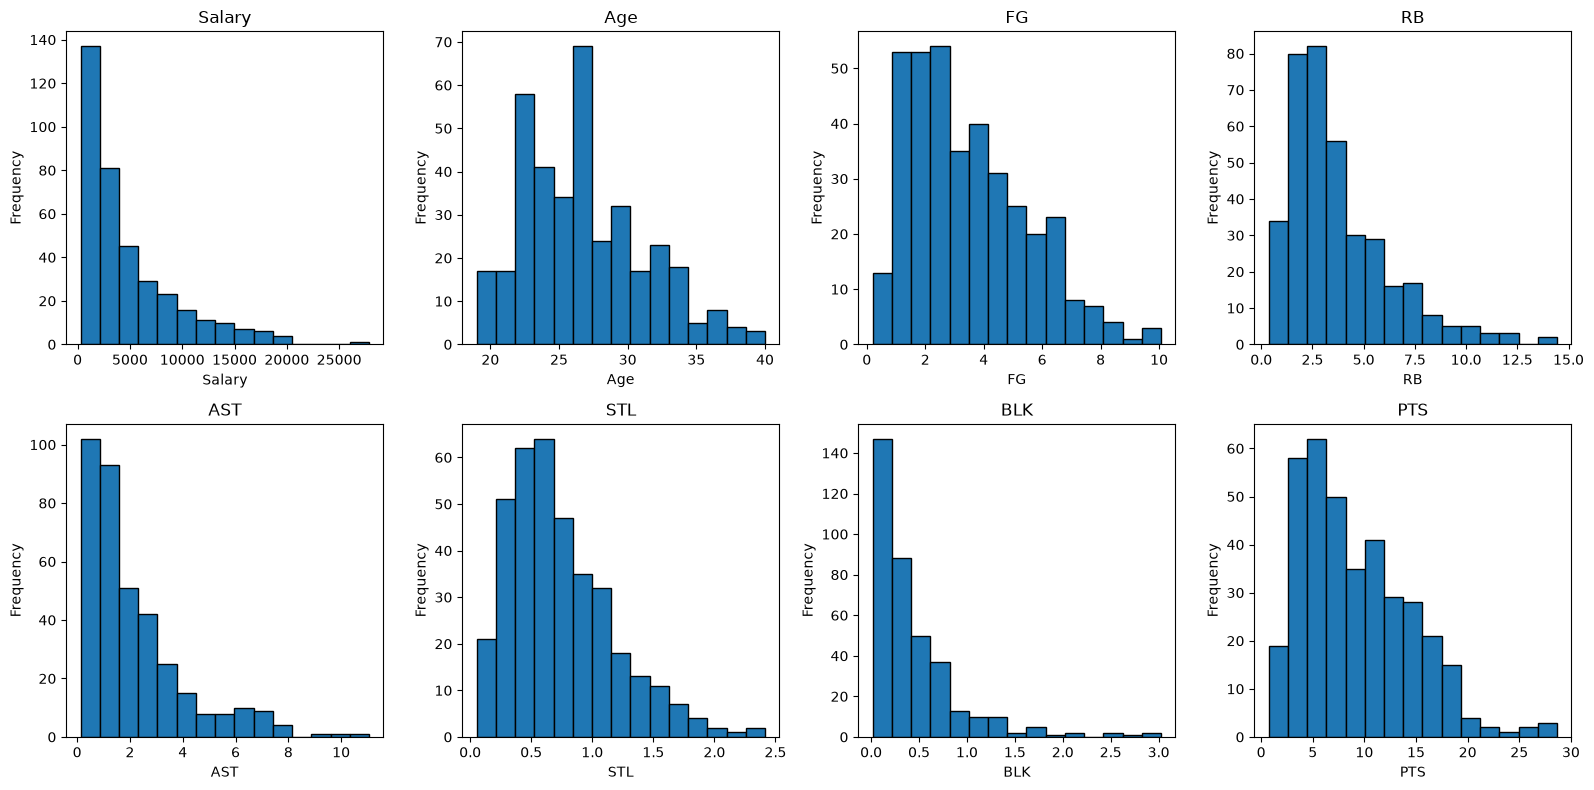

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

data = pd.read_parquet("nba_pgdata.parquet")
# histogram
var = ["Salary", "Age", "FG", "RB", "AST", "STL", "BLK", "PTS"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, var in zip(axes.flat, var):
    ax.hist(data[var].dropna(), bins=15, edgecolor="black")
    ax.set_title(var)
    ax.set_xlabel(var)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The distributions of Salary, AST, and BLK are strongly right-skewed.

The disributions of FG, RB, STL, and PTS are moderately right-skewed.

The disribution of Age is sllightly right-skewed.


### Scatterplot


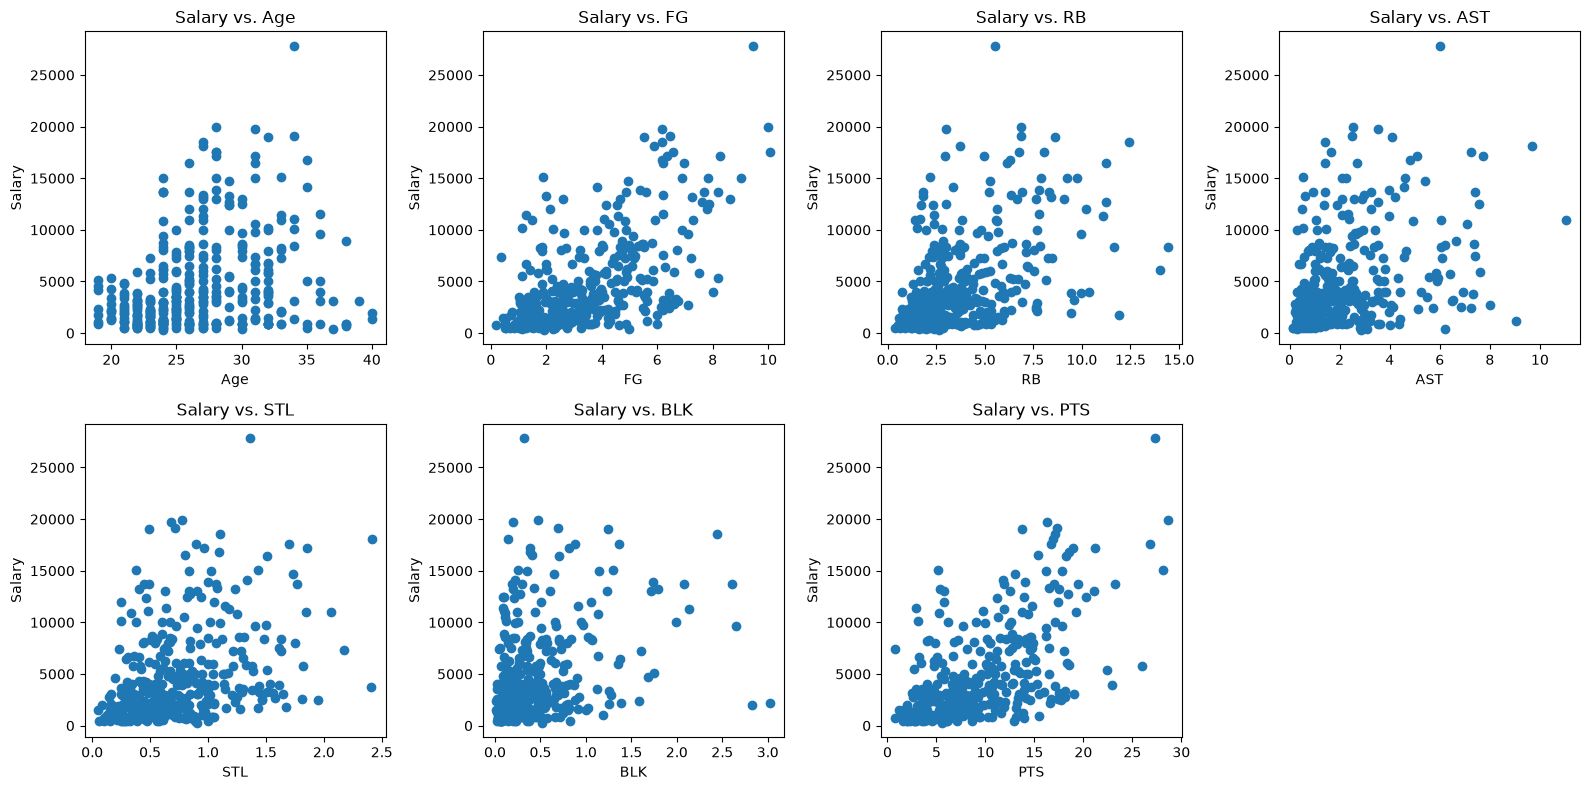

In [16]:
pred = ["Age", "FG", "RB", "AST", "STL", "BLK", "PTS"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, var in zip(axes.flat, pred):
    plot_data = data[[var, "Salary"]].dropna()
    ax.scatter(plot_data[var], plot_data["Salary"])
    ax.set_title(f"Salary vs. {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Salary")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


FG and PTS show a strong positive linear relationship with Salary.

AST, STL, and BLK have no clear linear relationship with Salary.

Age shows a weak positive linear relationship with Salary.


### Regression A


In [17]:
import statsmodels.formula.api as smf

model_A = smf.ols("Salary ~ Age + FG + RB + AST + STL + BLK", data=data).fit()

print(model_A.summary())


                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.492
Model:                            OLS   Adj. R-squared:                  0.484
Method:                 Least Squares   F-statistic:                     58.63
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.59e-50
Time:                        23:40:00   Log-Likelihood:                -3517.9
No. Observations:                 370   AIC:                             7050.
Df Residuals:                     363   BIC:                             7077.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -8724.6669   1131.833     -7.708      0.0

**Interpret the estimated coefficients and R^2**


The coefficient on Age is 312.092, which means that one additional year in Age is associated with a $312,092 increase in Salary while holding other variables constant.

The coefficient on FG is 1156.982, which means that a one-unit increase in FG is associated with a $1,156,982 increase in salary while holding other variables constant.

The coefficient on RB is 223.312, which means that a one-unit increase in RB is associated with a $223,312 increase in salary while holding other variables constant.

The coefficient on AST is 280.498, which means that a one-unit increase in AST is associated with a $280,498 increase in salary while holding other variables constant.

The coefficient on STL is -1,064.07, which means that a one-unit increase in STL is associated with a $1,064,070 decrease in salary while holding other variables constant.

The coefficient on BLK is 1,071.1, which means that a one-unit increase in BLK is associated with a $1,071,100 increase in salary while holding other variables constant.


**Significant Variables:** Age, FG, BLK

**Insignificant Variables:** RB, AST, STL
Each independent variable is tested using a two-sided t-test.

H0: The coefficient on each independent variable is equal to zero.

Ha: The coefficient on each independent variable is not equal to zero.


Most of the coefficient signs make sense. For example, Age, FG, and BLK have positive coefficients, which suggests that older players and players with higher FG and BLK values tend to receive higher salaries while holding other variables constant. However, it is unexpected that STL has a negative coefficient. However, STL is not statistically significant at the 5% level.


The R-squared is 0.492, which means that 49.2% of the variation in the salary can be explained by Age, FG, BLK, RB, AST, and STL.


#### Regression Plots


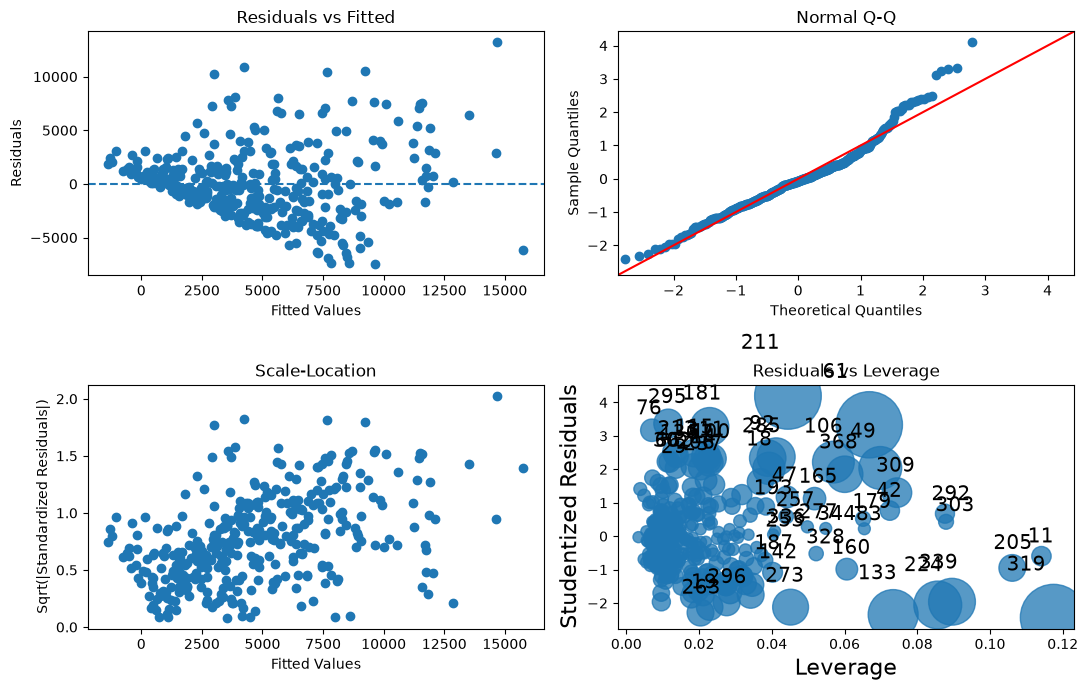

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# fitted values and residuals
fitted = model_A.fittedvalues
residuals = model_A.resid

# standardized residuals
influence = model_A.get_influence()
std_residuals = influence.resid_studentized_internal

# Residuals vs Fitted
axes[0, 0].scatter(fitted, residuals)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Residuals vs Fitted")
axes[0, 0].set_xlabel("Fitted Values")
axes[0, 0].set_ylabel("Residuals")

# Normal Q-Q
sm.qqplot(std_residuals, line="45", ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")

# Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_residuals)))
axes[1, 0].set_title("Scale-Location")
axes[1, 0].set_xlabel("Fitted Values")
axes[1, 0].set_ylabel("Sqrt(|Standardized Residuals|)")

# Residuals vs Leverage
sm.graphics.influence_plot(model_A, ax=axes[1, 1], criterion="cooks")
axes[1, 1].set_title("Residuals vs Leverage")

plt.tight_layout()
plt.show()


In the Residuals vs Fitted plot, the residuals show a clear fan-shaped pattern, which suggests that the error variance is not constant.

In the normal Q-Q plot,most points follow the diagonal line, but some points deviate from the line, which suggests that the residuals are not normally distributed.

The points in the scale-location plot show an upward trend, which suggests heteroskedasticity.

Residuals vs. Leverage plot shows that some observations have relatively high leverage and large Cook's distance values. These observations may strongly influence the regression results.


### Regression B


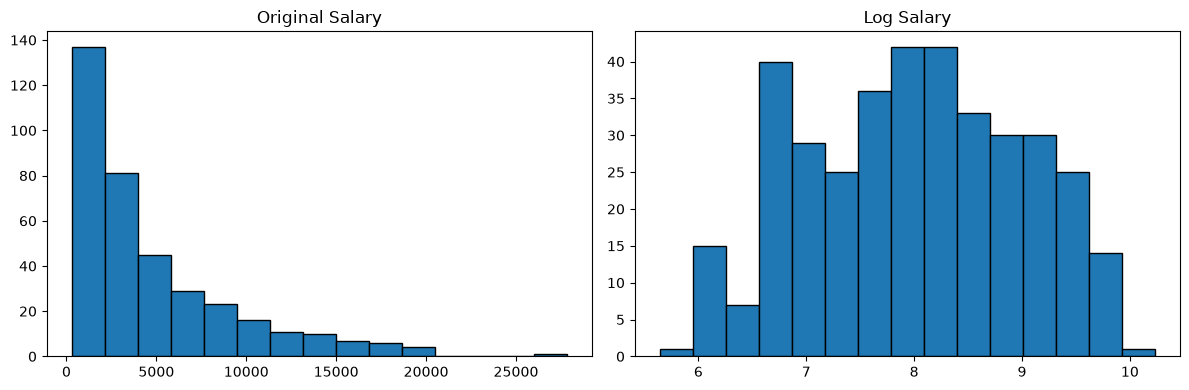

In [19]:
data["log_Salary"] = np.log(data["Salary"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(data["Salary"].dropna(), bins=15, edgecolor="black")
axes[0].set_title("Original Salary")

axes[1].hist(data["log_Salary"].dropna(), bins=15, edgecolor="black")
axes[1].set_title("Log Salary")

plt.tight_layout()
plt.show()

log_Salary is approximately normally distributed, which suggests that log transformation can significant reduce the influence of outliers.


In [20]:
model_B = smf.ols("log_Salary ~ Age + FG + RB + AST + STL + BLK", data=data).fit()

print(model_B.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.455
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     50.60
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           4.35e-45
Time:                        23:40:00   Log-Likelihood:                -410.42
No. Observations:                 370   AIC:                             834.8
Df Residuals:                     363   BIC:                             862.2
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.3022      0.255     20.803      0.0

**Interpretation of Coefficients**

The coefficient on Age is 0.0577, which means that one additional year of age is associated with a 5.94% increase in salary while holding other variables constant.

The coefficient on FG is 0.2077, which means that a one-unit increase in FG is associated with a 23.08% increase in salary while holding other variables constant.

The coefficient on RB is 0.0667, which means that a one-unit increase in RB is associated with a 6.90% increase in salary while holding other variables constant.

The coefficient on AST is 0.0463, which means that a one-unit increase in AST is associated with a 4.74% increase in salary while holding other variables constant.

The coefficient on STL is 0.0017, which means that a one-unit increase in STL is associated with a 0.17% increase in salary while holding other variables constant.

The coefficient on BLK is 0.2104, which means that a one-unit increase in BLK is associated with a 23.42% increase in salary while holding other variables constant.

**Significant Variables:** Age, FG, RB

**Insignificant Variables:** BLK, AST, STL

The R-squared is 0.455, which means that 45.5% of the variation in the salary can be explained by Age, FG, BLK, RB, AST, and STL.


#### Regression Plots


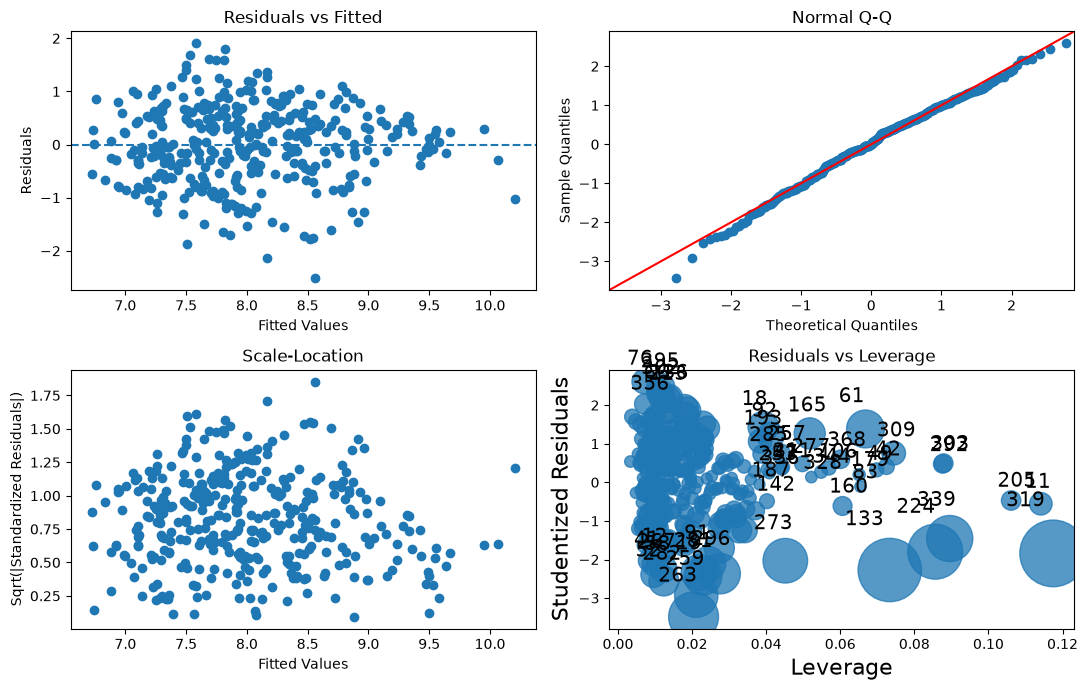

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# fitted values and residuals
fitted = model_B.fittedvalues
residuals = model_B.resid

# standardized residuals
influence = model_B.get_influence()
std_residuals = influence.resid_studentized_internal

# Residuals vs Fitted
axes[0, 0].scatter(fitted, residuals)
axes[0, 0].axhline(0, linestyle="--")
axes[0, 0].set_title("Residuals vs Fitted")
axes[0, 0].set_xlabel("Fitted Values")
axes[0, 0].set_ylabel("Residuals")

# Normal Q-Q
sm.qqplot(std_residuals, line="45", ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")

# Scale-Location
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_residuals)))
axes[1, 0].set_title("Scale-Location")
axes[1, 0].set_xlabel("Fitted Values")
axes[1, 0].set_ylabel("Sqrt(|Standardized Residuals|)")

# Residuals vs Leverage
sm.graphics.influence_plot(model_B, ax=axes[1, 1], criterion="cooks")
axes[1, 1].set_title("Residuals vs Leverage")

plt.tight_layout()
plt.show()

The diagnostic plots suggest that Model B performs better than Model A. The log transformation improves the normality of the residuals and reduces the heteroskedasticity problem. However, some potentially influential observations remain.


### Regression C


In [22]:
model_C = smf.ols("log_Salary ~ Age + FG + RB + AST + STL + BLK + PTS", data=data).fit()

print(model_C.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.465
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     45.01
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.23e-45
Time:                        23:40:01   Log-Likelihood:                -407.01
No. Observations:                 370   AIC:                             830.0
Df Residuals:                     362   BIC:                             861.3
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.2968      0.253     20.944      0.0

When PTS is included in the model, the coefficient on FG(p=0.368) becomes negative and insignificant. BLK(p=0.032) becomes one significant predictor, and the added PTS(0.01) is also one significant predictor. This may be caused by multicollinearity between FG and PTS. The two variables may share similar information because they are related to scoring performance.


### Regression D


In [23]:
from sklearn.preprocessing import StandardScaler

df = data.copy()

df[["log_Salary", "Age", "RB", "AST", "STL", "BLK", "PTS"]] = (
    StandardScaler().fit_transform(
        df[["log_Salary", "Age", "RB", "AST", "STL", "BLK", "PTS"]]
    )
)

model_D = smf.ols("log_Salary ~ Age + RB + AST + STL + BLK + PTS", data=df).fit()

print(model_D.summary())

                            OLS Regression Results                            
Dep. Variable:             log_Salary   R-squared:                       0.464
Model:                            OLS   Adj. R-squared:                  0.455
Method:                 Least Squares   F-statistic:                     52.41
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           2.41e-46
Time:                        23:40:01   Log-Likelihood:                -409.58
No. Observations:                 370   AIC:                             833.2
Df Residuals:                     363   BIC:                             860.6
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.006e-16      0.038  -2.62e-15      1.0

Standardized coefficients allow us to directly compare the strength of the relationships between different independent variables and the dependent variable. This is because all variables are measured on the same standardized scale.

For example, PTS has a standardized coefficient of 0.4279, which means that a one-standard-deviation increase in PTS is associated with a 0.4279 standard-deviation increase in log Salary while holding other variables constant. The coefficient on Age is 0.2537, which means that a one-standard-deviation increase in Age is associated with a 0.2537 standard-deviation increase in log Salary while holding other variables constant. Therefore, PTS has a stronger positive relationship with log Salary than Age.


## Hot Hand Hypothesis Testing

### Conditional Probability Approach


In [24]:
shooting_table = pd.DataFrame(
    {
        "Player": ["A", "B", "C", "D", "E", "F", "G", "H", "I"],
        "prob_hit_after_miss": [0.56, 0.51, 0.46, 0.60, 0.47, 0.51, 0.58, 0.52, 0.71],
        "prob_hit_overall": [0.50, 0.52, 0.46, 0.56, 0.47, 0.46, 0.54, 0.52, 0.62],
        "prob_hit_after_hit": [0.49, 0.53, 0.46, 0.55, 0.45, 0.43, 0.53, 0.51, 0.57],
    }
)

shooting_table["diff_after_hit_minus_after_miss"] = (
    shooting_table["prob_hit_after_hit"] - shooting_table["prob_hit_after_miss"]
)

print(shooting_table)

  Player  prob_hit_after_miss  prob_hit_overall  prob_hit_after_hit  \
0      A                 0.56              0.50                0.49   
1      B                 0.51              0.52                0.53   
2      C                 0.46              0.46                0.46   
3      D                 0.60              0.56                0.55   
4      E                 0.47              0.47                0.45   
5      F                 0.51              0.46                0.43   
6      G                 0.58              0.54                0.53   
7      H                 0.52              0.52                0.51   
8      I                 0.71              0.62                0.57   

   diff_after_hit_minus_after_miss  
0                            -0.07  
1                             0.02  
2                             0.00  
3                            -0.05  
4                            -0.02  
5                            -0.08  
6                            -

**Bird's eye view**

If a hot hand exists, a player should shoot better after a hit than after a miss, so the difference (P(hit | 1 hit) − P(hit | 1 miss)) should be positive.

In the table, only Player B has a positive difference (+0.02), Player C has a difference of 0, and the other seven players have negative differences (from −0.01 to −0.14). So by eye, only Player B looks even slightly hot, and that gap is tiny. Most players actually shoot slightly better after a miss than after a hit.

The data does not show a clear sign of a hot hand, but this is only an impression, so we need a statistical test to be sure.


**Hypothesis test setup**

Let d be the difference P(hit | 1 hit) − P(hit | 1 miss) for a player, and let μ_d be the average of d across players.

- Null hypothesis (H0): μ_d = 0. There is no hot hand, so a player is equally accurate after a hit and after a miss.
- Alternative hypothesis (Ha): μ_d > 0. There is a hot hand, so players shoot better after a hit than after a miss.

**How much data do we have?** Only 9 players, so 9 differences (n = 9). This is a small sample.

**Which distribution?** Because the sample is small and the true standard deviation is unknown, we use a t distribution with n − 1 = 8 degrees of freedom (one-sided test).


In [25]:
import math
from scipy import stats

difference_list = shooting_table["diff_after_hit_minus_after_miss"]

number_of_players = len(difference_list)

mean_difference = difference_list.mean()

std_difference = difference_list.std()

standard_error = std_difference / math.sqrt(number_of_players)

t_statistic = mean_difference / standard_error

degrees_of_freedom = number_of_players - 1

p_value_one_sided = stats.t.sf(t_statistic, degrees_of_freedom)

print("Number of players:", number_of_players)
print("Mean difference:", mean_difference)
print("Std of differences:", std_difference)
print("Standard error:", standard_error)
print("t statistic:", t_statistic)
print("Degrees of freedom:", degrees_of_freedom)
print("One-sided p-value:", p_value_one_sided)

Number of players: 9
Mean difference: -0.04444444444444443
Std of differences: 0.04876246279442599
Standard error: 0.016254154264808664
t statistic: -2.7343437080986512
Degrees of freedom: 8
One-sided p-value: 0.9871636162151614


**Conclusion**

The mean difference is −0.044: on average, these players shot about 4.4 percentage points worse after a hit than after a miss. The t statistic is −2.73 with 8 degrees of freedom, and the one-sided p-value is 0.987.

Because the p-value is far above 0.05, we fail to reject H0. The data give no evidence of a hot hand, and the average difference even points in the opposite direction.

This does not prove that a hot hand does not exist. With only 9 players and a measure that looks at just the previous shot, the test may not have enough power to detect a small effect.


### Streaks Approach


#### Simulation Model

A run is a consecutive sequence of identical shooting outcomes. Both runs of hits and runs of misses are counted. For example, `HHMHMMHHH` contains five runs.

Under the null hypothesis, each player’s shots are independent Bernoulli trials with a constant success probability equal to the player’s overall shooting percentage. For each player, we simulate 200,000 sequences with the same number of shots as observed in the data.

The number of runs in each sequence is calculated as:

$$
R = 1 + \sum_{t=2}^{n}\mathbf{1}(X_t \neq X_{t-1}).
$$

The mean and sample standard deviation of the simulated run counts estimate the expected number of runs and its standard deviation under the null hypothesis.


In [26]:
players = pd.DataFrame(
    {
        "Player": list("ABCDEFGHI"),
        "Hit probability": [0.50, 0.52, 0.46, 0.56, 0.47, 0.46, 0.54, 0.52, 0.62],
        "Number of shots": [248, 884, 419, 339, 272, 451, 433, 351, 403],
        "Actual runs": [128, 431, 203, 172, 134, 245, 227, 176, 220],
    }
)

rng = np.random.default_rng(453)

n_simulations = 200_000
batch_size = 2_000
alpha = 0.05

results = []

for _, player in players.iterrows():
    p = float(player["Hit probability"])
    n = int(player["Number of shots"])
    actual_runs = int(player["Actual runs"])

    simulated_runs = np.empty(n_simulations, dtype=np.int32)

    for start in range(0, n_simulations, batch_size):
        stop = min(start + batch_size, n_simulations)

        shots = rng.random((stop - start, n)) < p

        simulated_runs[start:stop] = 1 + np.count_nonzero(
            shots[:, 1:] != shots[:, :-1], axis=1
        )

    expected_runs = simulated_runs.mean()
    sd_runs = simulated_runs.std(ddof=1)

    p_value = (np.count_nonzero(simulated_runs <= actual_runs) + 1) / (
        n_simulations + 1
    )

    results.append(
        {
            "Player": player["Player"],
            "Number of shots": n,
            "Actual runs": actual_runs,
            "Expected runs": expected_runs,
            "SD of runs": sd_runs,
            "One-sided p-value": p_value,
            "Reject H0": p_value < alpha,
        }
    )

streaks_results = pd.DataFrame(results)

print(
    streaks_results.to_string(
        index=False,
        formatters={
            "Expected runs": "{:.2f}".format,
            "SD of runs": "{:.2f}".format,
            "One-sided p-value": "{:.4f}".format,
        },
    )
)

Player  Number of shots  Actual runs Expected runs SD of runs One-sided p-value  Reject H0
     A              248          128        124.53       7.86            0.6931      False
     B              884          431        441.77      14.90            0.2451      False
     C              419          203        208.66      10.28            0.3076      False
     D              339          172        167.59       9.32            0.7017      False
     E              272          134        136.02       8.25            0.4267      False
     F              451          245        224.57      10.67            0.9756      False
     G              433          227        215.62      10.47            0.8716      False
     H              351          176        175.72       9.36            0.5324      False
     I              403          220        190.42      10.55            0.9980      False


#### Hypothesis Test

For each player, the hypotheses are:

- **H₀:** Shooting outcomes are independent, with a constant hit probability equal to the player’s overall shooting percentage.
- **Hₐ:** Shooting outcomes exhibit streakiness, producing fewer runs than expected under the independent-shots model.

A hot hand would cause hits to cluster together, resulting in fewer and longer runs. Therefore, we use a lower-tailed test with significance level $\alpha = 0.05$.

The p-value is the probability, under the null model, of observing a run count at least as small as the actual count:

$$
p\text{-value} = P_{H_0}(R \leq R_{\text{observed}}).
$$

We estimate this probability using the proportion of simulated sequences whose run counts are less than or equal to the observed count, with a Monte Carlo adjustment:

$$
\widehat{p}
=
\frac{1 + \#\{R_{\text{simulated}} \leq R_{\text{observed}}\}}
{200{,}000 + 1}.
$$


#### Conclusion

All nine players have one-sided p-values greater than 0.05. Therefore, we fail to reject the null hypothesis for every player.

Players B, C, and E have fewer observed runs than expected, but these differences are not statistically significant. Player B has the smallest p-value, approximately 0.2451, which is still well above 0.05.

Players A, D, F, G, H, and I have more observed runs than expected. Their results do not support the prediction of fewer runs associated with a hot hand. Player I’s high lower-tail p-value reflects a run count above the model’s expectation; it does not provide evidence of a hot hand.

The runs data do not provide statistically significant evidence that any of these players has a hot hand. This does not establish that the hot hand does not exist; it means that this test does not detect it in these data.


## Critical Thinking


In [27]:
basketball_data = pd.read_parquet("BasketballRelationships.parquet")
baseball_data = pd.read_parquet("BaseballRelationships.parquet")

print(basketball_data.head())
print(baseball_data.head())

   attempts  percentage  points
0       905    0.438674    1057
1      1318    0.484067    1560
2       638    0.445141     705
3       474    0.474684     555
4      1489    0.449295    1920
   atbats  hits       avg
0     384    97  0.252604
1     296    84  0.283784
2     334    94  0.281437
3     626   176  0.281150
4     558   130  0.232975


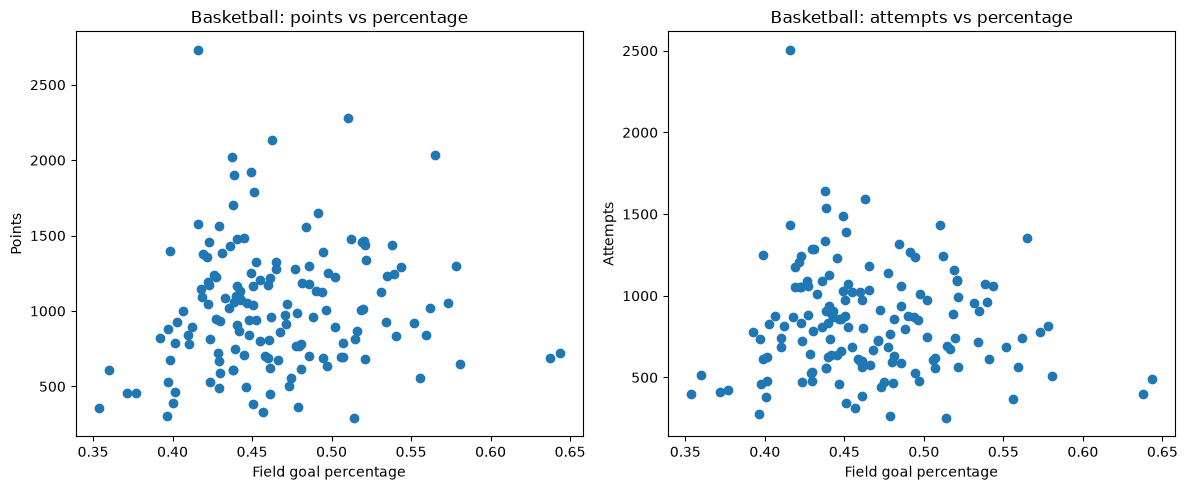

In [28]:
figure_basketball, axes_basketball = plt.subplots(1, 2, figsize=(12, 5))

axes_basketball[0].scatter(basketball_data["percentage"], basketball_data["points"])
axes_basketball[0].set_xlabel("Field goal percentage")
axes_basketball[0].set_ylabel("Points")
axes_basketball[0].set_title("Basketball: points vs percentage")

axes_basketball[1].scatter(basketball_data["percentage"], basketball_data["attempts"])
axes_basketball[1].set_xlabel("Field goal percentage")
axes_basketball[1].set_ylabel("Attempts")
axes_basketball[1].set_title("Basketball: attempts vs percentage")

plt.tight_layout()
plt.show()

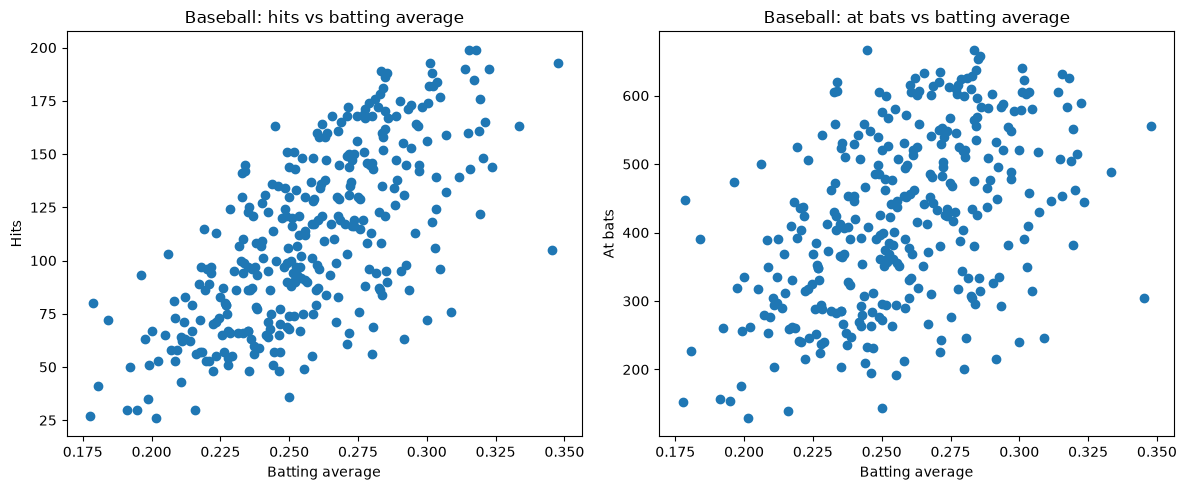

In [29]:
figure_baseball, axes_baseball = plt.subplots(1, 2, figsize=(12, 5))

axes_baseball[0].scatter(baseball_data["avg"], baseball_data["hits"])
axes_baseball[0].set_xlabel("Batting average")
axes_baseball[0].set_ylabel("Hits")
axes_baseball[0].set_title("Baseball: hits vs batting average")

axes_baseball[1].scatter(baseball_data["avg"], baseball_data["atbats"])
axes_baseball[1].set_xlabel("Batting average")
axes_baseball[1].set_ylabel("At bats")
axes_baseball[1].set_title("Baseball: at bats vs batting average")

plt.tight_layout()
plt.show()

**Discussion**

**1. What might make the hot hand easier or more difficult to observe in either sport?**

Basketball gives us plenty of data since a player takes a lot of shots every game. But a hot hand is hard to see because the other team reacts to it. If a player is on fire, the defense will probably guard him more tightly, and he may also start taking harder shots, so his shooting percentage drops back down and the effect gets hidden. Shot difficulty also changes from shot to shot, so a made or missed shot does not tell us much about his form by itself. Baseball is even harder. A hitter only gets about four at bats a game, so there are very few chances in a row to see a streak, and he faces different pitchers and defenses from game to game.

**2. What would you need to do in order to establish that the hot hand exists in basketball?**

Neither our conditional probability test nor our streaks analysis found evidence of a hot hand, but that does not rule it out. To really test it, we would need shot-by-shot data and we would have to compare shots taken in similar situations (same distance, same defender) after a make and after a miss. A controlled experiment would be even better, for example players shooting from the same spot with no defender, because that takes away shot selection and defense.

**3. How you would build a regression model to try to establish that a hot hand exists?**

I would use a logistic regression, because each shot either goes in (1) or it does not (0). The main predictors would be the results of the player's previous shots, for example whether he made his last shot, or how many of his last few shots he made. If previous makes have a positive and significant effect on the next shot, even after controlling for the other variables, that would be evidence of a hot hand.

**4. What would be critical predictor variables?**

The results of the previous shots would be the key variable. I would also control for how far the shot is (3 pointer or mid-range), how close the nearest defender is, and who the player is, since players differ in skill. Things like home or away, time left and score margin could also matter, and so could fatigue (minutes played).

**5. How much data would you need?**

A lot. A single shot is very noisy and a hot hand effect is probably small, so we would need thousands of shots per player to pick it up. The players in Table 2 only took between 248 and 884 shots, which is not nearly enough. That is another reason our tests may have missed an effect.
